# Technical Assessment: Investor Intelligence Engine Evaluation Notebook

This notebook provides an in-depth empirical evaluation of the **Investor Intelligence Engine prototype**.
It systematically evaluates:
1. **Extraction Pipeline**: Parsing unstructured notes into structured attributes (Ticket Sizes, Sectors, Stages, Signals).
2. **Entity Resolution & Deduplication**: Multi-tier matching (domain canonicalization + RapidFuzz token sorting + DSU clustering) and false-positive prevention.
3. **Conflict Detection & Source Provenance**: Flagging disjoint ticket ranges, geographic discrepancies, and stage divergences with audit trails.
4. **Data Completeness & Quality Metrics**: Quantitative scoring and missing field audits.
5. **Visual Analytics**: Distribution of statuses, sectors, and completeness scores.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Ensure root workspace is in sys.path
sys.path.insert(0, str(Path.cwd()))

from engine import InvestorExtractor, InvestorIntelligenceEngine, get_default_dataset_path, load_default_dataset

print("✓ Environment initialized successfully.")
print(f"✓ Using dataset from: {get_default_dataset_path()}")


✓ Environment initialized successfully.
✓ Using dataset from: C:\Users\DELL\Desktop\Investor Intelligence Engine\data\investors.json


## 1. Synthetic Dataset Inspection (`data/investors.json`)

The synthetic dataset contains 10 unstructured/semi-structured records deliberately engineered to reflect real-world venture capital data challenges:
- **Duplicates (7 records across 3 entities)**: Multiple entities with variations in naming (`Apex Horizon Ventures`, `Apex Horizon Capital LLC`, `Apex Horizon VC`, `Bluecrest Growth Partners`, `Bluecrest Ventures`, `Nordic Frontier Fund`, `Nordic Frontier VC`).
- **Missing Information (3 records)**: Missing ticket sizes, missing geography, and unlisted websites (`raw-004`, `raw-007`, `raw-008`).
- **Discrepancies & Conflicts (5 records across 2 entities)**: Disjoint check sizes ($1.5M-$3M vs $5M-$10M vs $250k-$500k), conflicting HQs (San Francisco vs London), and stage divergences (Seed vs Growth Series B/C).
- **Negative Controls & Baseline**: Distinct firms sharing keywords (`Horizon Ventures` vs `Apex Horizon Ventures`) and complete single-source baselines (`Soma Quantum Capital`).


In [2]:
raw_records = load_default_dataset()

# Table 1: Comprehensive Ingested Records Overview
raw_overview = []
for r in raw_records:
    meta = r.get("metadata", {})
    raw_overview.append({
        "Source ID": r["source_id"],
        "Raw Name": r["raw_name"],
        "Website": r.get("raw_website") or "[Missing / None]",
        "Dataset Role": meta.get("dataset_role", "Raw Record"),
        "Target Cluster": meta.get("expected_cluster", "Unknown"),
        "Challenges & Notes": meta.get("challenge_description", r["raw_text"][:80] + "...")
    })

raw_df = pd.DataFrame(raw_overview)
print(f"Total Raw Ingested Records: {len(raw_df)}")
display(raw_df) if 'display' in globals() else print(raw_df.to_string())


Total Raw Ingested Records: 10
  Source ID                   Raw Name                        Website                             Dataset Role             Target Cluster                                                                                                             Challenges & Notes
0   raw-001      Apex Horizon Ventures     https://www.apexhorizon.vc                  Duplicate & Conflicting      Apex Horizon Ventures               Duplicate (primary profile); check size ($1.5M-$3M) conflicts with raw-002 ($5M-$10M) and raw-003 ($250k-$500k).
1   raw-002   Apex Horizon Capital LLC                 apexhorizon.vc                  Duplicate & Conflicting      Apex Horizon Ventures                Duplicate (legal LLC alias); reports growth ticket size ($5M-$10M) which diverges >2x from raw-001 ($1.5M-$3M).
2   raw-003            Apex Horizon VC  https://apexhorizon.vc/europe                  Duplicate & Conflicting      Apex Horizon Ventures  Duplicate (regional VC scout alias)

In [3]:
print("=" * 80)
print("1.1 DUPLICATE RECORDS AUDIT (7 records clustered into 3 canonical entities)")
print("=" * 80)

dup_rows = []
for r in raw_records:
    meta = r.get("metadata", {})
    if meta.get("is_duplicate"):
        dup_rows.append({
            "Cluster": meta.get("duplicate_group"),
            "Source ID": r["source_id"],
            "Source Name": r["source_name"],
            "Raw Entity Name": r["raw_name"],
            "Website / Domain": r.get("raw_website") or "[None]",
            "Expected Canonical": meta.get("expected_cluster"),
            "Deduplication Target": meta.get("challenge_description")
        })

dup_df = pd.DataFrame(dup_rows).sort_values(by=["Cluster", "Source ID"]).reset_index(drop=True)
display(dup_df) if 'display' in globals() else print(dup_df.to_string())


1.1 DUPLICATE RECORDS AUDIT (7 records clustered into 3 canonical entities)
           Cluster Source ID                                Source Name            Raw Entity Name               Website / Domain         Expected Canonical                                                                                                           Deduplication Target
0     Apex Horizon   raw-001                     PitchBook 2024 Profile      Apex Horizon Ventures     https://www.apexhorizon.vc      Apex Horizon Ventures               Duplicate (primary profile); check size ($1.5M-$3M) conflicts with raw-002 ($5M-$10M) and raw-003 ($250k-$500k).
1     Apex Horizon   raw-002  TechCrunch Article (Funding Announcement)   Apex Horizon Capital LLC                 apexhorizon.vc      Apex Horizon Ventures                Duplicate (legal LLC alias); reports growth ticket size ($5M-$10M) which diverges >2x from raw-001 ($1.5M-$3M).
2     Apex Horizon   raw-003   AngelList / European Ecosystem Directory 

In [4]:
print("=" * 80)
print("1.2 MISSING INFORMATION AUDIT (3 records with incomplete attributes)")
print("=" * 80)

missing_rows = []
for r in raw_records:
    meta = r.get("metadata", {})
    missing_attrs = meta.get("missing_fields", [])
    if meta.get("has_missing_data") or missing_attrs:
        missing_rows.append({
            "Source ID": r["source_id"],
            "Source Name": r["source_name"],
            "Raw Entity Name": r["raw_name"],
            "Missing Fields": ", ".join(missing_attrs) if missing_attrs else "None",
            "Website Present": "No" if not r.get("raw_website") else "Yes",
            "Role / Impact": meta.get("dataset_role"),
            "Audit Note": meta.get("challenge_description")
        })

missing_df = pd.DataFrame(missing_rows).reset_index(drop=True)
display(missing_df) if 'display' in globals() else print(missing_df.to_string())


1.2 MISSING INFORMATION AUDIT (3 records with incomplete attributes)
  Source ID                            Source Name            Raw Entity Name                   Missing Fields Website Present                          Role / Impact                                                                                                Audit Note
0   raw-004                 SEC Form D Filing Note  Bluecrest Growth Partners           ticket_size, geography             Yes  Duplicate, Missing Data & Conflicting  Duplicate; missing check size & HQ; reports Series B/C expansion (conflicts with Seed stage in raw-005).
1   raw-007     Founder Community Sheet Submission         Nordic Frontier VC                          website              No               Duplicate & Missing Data             Duplicate (community submission); missing official website; ticket agrees with raw-006 range.
2   raw-008  Substack Bio (Climate Capital Digest)      Verdant Seed Partners  ticket_size, geography, website     

In [5]:
print("=" * 80)
print("1.3 CONFLICTING RECORDS AUDIT (5 records introducing cross-source contradictions)")
print("=" * 80)

conflict_rows = []
for r in raw_records:
    meta = r.get("metadata", {})
    if meta.get("has_conflicts"):
        conflict_rows.append({
            "Cluster": meta.get("duplicate_group"),
            "Source ID": r["source_id"],
            "Source Name": r["source_name"],
            "Raw Entity Name": r["raw_name"],
            "Conflict Field(s)": ", ".join(meta.get("conflict_fields", [])),
            "Contradiction Details": meta.get("challenge_description")
        })

conflict_df = pd.DataFrame(conflict_rows).sort_values(by=["Cluster", "Source ID"]).reset_index(drop=True)
display(conflict_df) if 'display' in globals() else print(conflict_df.to_string())


1.3 CONFLICTING RECORDS AUDIT (5 records introducing cross-source contradictions)
        Cluster Source ID                                Source Name            Raw Entity Name       Conflict Field(s)                                                                                                          Contradiction Details
0  Apex Horizon   raw-001                     PitchBook 2024 Profile      Apex Horizon Ventures  ticket_size, geography               Duplicate (primary profile); check size ($1.5M-$3M) conflicts with raw-002 ($5M-$10M) and raw-003 ($250k-$500k).
1  Apex Horizon   raw-002  TechCrunch Article (Funding Announcement)   Apex Horizon Capital LLC             ticket_size                Duplicate (legal LLC alias); reports growth ticket size ($5M-$10M) which diverges >2x from raw-001 ($1.5M-$3M).
2  Apex Horizon   raw-003   AngelList / European Ecosystem Directory            Apex Horizon VC  ticket_size, geography  Duplicate (regional VC scout alias); reports London HQ (

## 2. Executing the Investor Intelligence Engine Pipeline

The pipeline runs extraction, deduplication, conflict detection, and canonical aggregation in a single coordinated pass.


In [6]:
engine = InvestorIntelligenceEngine()
canonical_entities = engine.process_records(raw_records)
metrics = engine.get_metrics()

print("✓ Pipeline execution completed.")
print(f"• Input Raw Records:        {metrics['total_raw_records']}")
print(f"• Output Canonical Entities: {metrics['total_canonical_entities']}")
print(f"• Deduplication Rate:       {metrics['deduplication_rate_percent']}%")
print(f"• Average Completeness:     {int(metrics['average_completeness_score'] * 100)}%")
print(f"• Status Breakdown:         {metrics['status_breakdown']}")
print(f"• Conflicts by Field:       {metrics['conflicts_by_field']}")


✓ Pipeline execution completed.
• Input Raw Records:        10
• Output Canonical Entities: 6
• Deduplication Rate:       40.0%
• Average Completeness:     91%
• Status Breakdown:         {'CONFLICT_DETECTED': 2, 'SINGLE_SOURCE_UNVERIFIED': 2, 'VERIFIED_MULTI_SOURCE': 1, 'INCOMPLETE_PROFILE': 1}
• Conflicts by Field:       {'ticket_size': 1, 'geography': 1, 'stages': 1}


## 3. Entity Resolution & Deduplication Evaluation

We verify that:
1. **Transitive duplicates** across multiple sources are clustered into canonical entities.
2. **False positives** are prevented: Generic keyword matches (e.g., *Horizon Ventures*) must remain separate from *Apex Horizon Ventures*.


In [7]:
dedup_records = []
for e in canonical_entities:
    dedup_records.append({
        "ID": e.id,
        "Canonical Name": e.canonical_name,
        "Sources Count": len(e.sources),
        "Aliases": ", ".join(e.aliases) if e.aliases else "None",
        "Status": e.status,
        "Ticket Size": e.ticket_size.formatted_range if e.ticket_size else "Unknown",
        "Primary HQ": e.headquarters or "Unknown",
        "Completeness": f"{int(e.completeness_score * 100)}%"
    })

dedup_df = pd.DataFrame(dedup_records)
display(dedup_df) if 'display' in globals() else print(dedup_df.to_string())

# Verification Assertions
apex = next(e for e in canonical_entities if "Apex Horizon" in e.canonical_name)
assert len(apex.sources) == 3, f"Expected 3 sources for Apex Horizon, got {len(apex.sources)}"

horizon = next(e for e in canonical_entities if e.canonical_name == "Horizon Ventures")
assert len(horizon.sources) == 1, "Horizon Ventures was falsely merged!"

print("\n✓ All deduplication and false-positive checks passed!")


        ID             Canonical Name  Sources Count                                    Aliases                    Status    Ticket Size         Primary HQ Completeness
0  inv-001      Apex Horizon Ventures              3  Apex Horizon Capital LLC, Apex Horizon VC         CONFLICT_DETECTED    $1.5M - $3M  San Francisco, CA         100%
1  inv-002  Bluecrest Growth Partners              2                         Bluecrest Ventures         CONFLICT_DETECTED    $1M - $2.5M         Boston, MA         100%
2  inv-006           Horizon Ventures              1                                       None  SINGLE_SOURCE_UNVERIFIED    $10M - $30M          Hong Kong         100%
3  inv-003       Nordic Frontier Fund              2                         Nordic Frontier VC     VERIFIED_MULTI_SOURCE  $550k - $2.2M  Helsinki, Finland         100%
4  inv-005       Soma Quantum Capital              1                                       None  SINGLE_SOURCE_UNVERIFIED      $2M - $4M         Austin, TX

## 4. Conflict Resolution & Evidence Provenance Audit

For each cluster, any contradictory evidence reported by diverse sources is audited and categorized by severity.


In [8]:
conflicted_entities = [e for e in canonical_entities if e.conflicts]
print(f"Entities with Flagged Conflicts: {len(conflicted_entities)}\n")

for e in conflicted_entities:
    print("================================================================================")
    print(f"CANONICAL ENTITY: {e.canonical_name} ({e.id}) | Status: {e.status}")
    print("================================================================================")
    print(f"Contributing Sources ({len(e.sources)}):")
    for s in e.sources:
        print(f"  • [{s.source_id}] {s.source_name}:")
        print(f"      - Check Size:   {s.ticket_size.formatted_range if s.ticket_size else 'None'}")
        print(f"      - Reported HQ:  {s.headquarters or 'None'}")
        print(f"      - Stages:       {', '.join(s.stages) if s.stages else 'None'}")

    print(f"\nFlagged Conflicts ({len(e.conflicts)}):")
    for c in e.conflicts:
        print(f"  [!] Field: {c.field.upper()} (Severity: {c.severity})")
        print(f"      Description:      {c.description}")
        print(f"      Suggested Action: {c.suggested_action}")
    print()


Entities with Flagged Conflicts: 2

CANONICAL ENTITY: Apex Horizon Ventures (inv-001) | Status: CONFLICT_DETECTED
Contributing Sources (3):
  • [raw-001] PitchBook 2024 Profile:
      - Check Size:   $1.5M - $3M
      - Reported HQ:  San Francisco, CA
      - Stages:       Seed, Series A
  • [raw-002] TechCrunch Article (Funding Announcement):
      - Check Size:   $5M - $10M
      - Reported HQ:  San Francisco, CA
      - Stages:       Series A, Series B, Growth
  • [raw-003] AngelList / European Ecosystem Directory:
      - Check Size:   $250k - $500k
      - Reported HQ:  London, UK
      - Stages:       Pre-Seed, Seed

Flagged Conflicts (2):
  [!] Field: TICKET_SIZE (Severity: HIGH)
      Description:      Discrepancy detected across sources: PitchBook 2024 Profile reports $1.5M - $3M, TechCrunch Article (Funding Announcement) reports $5M - $10M, AngelList / European Ecosystem Directory reports $250k - $500k
      Suggested Action: Review primary source filing vs media reports; pos

In [9]:
uncertain_entities = [e for e in canonical_entities if getattr(e, 'uncertain_matches', None)]
print(f"Entities with Flagged Uncertain Matches: {len(uncertain_entities)}\n")

for e in uncertain_entities:
    print("================================================================================")
    print(f"CANONICAL ENTITY: {e.canonical_name} ({e.id})")
    print("================================================================================")
    for u in e.uncertain_matches:
        print(f"  [?] Match Pair:        {u.source_a_name} ({u.source_a_id}) ⟷ {u.source_b_name} ({u.source_b_id})")
        print(f"      Confidence:        {int(u.confidence * 100)}% ({u.match_type})")
        print(f"      Reason:            {u.reason}")
        print(f"      Suggested Action:  {u.suggested_action}")
    print()


Entities with Flagged Uncertain Matches: 1

CANONICAL ENTITY: Nordic Frontier Fund (inv-003)
  [?] Match Pair:        Nordic Frontier Fund (raw-006) ⟷ Nordic Frontier VC (raw-007)
      Confidence:        95% (UNCORROBORATED_NAME_MATCH)
      Reason:            Exact normalized entity name: 'nordic frontier' (uncorroborated by domain)
      Suggested Action:  Matched with 95% confidence based on 'Exact normalized entity name: 'nordic frontier' (uncorroborated by domain)'. Manual review recommended because domain verification is absent.



## 5. Profile Completeness & Missing Data Audit

The engine systematically detects fields missing across *all* contributing sources and marks incomplete profiles for researcher attention.


In [10]:
completeness_data = []
for e in canonical_entities:
    completeness_data.append({
        "Canonical Name": e.canonical_name,
        "Completeness Score": e.completeness_score,
        "Status": e.status,
        "Missing Fields": ", ".join(e.missing_fields) if e.missing_fields else "None (Complete)"
    })

comp_df = pd.DataFrame(completeness_data)
display(comp_df) if 'display' in globals() else print(comp_df.to_string())

incomplete = next(e for e in canonical_entities if e.status == "INCOMPLETE_PROFILE")
print(f"\nIncomplete Entity Detected: '{incomplete.canonical_name}'")
print(f"Missing attributes: {incomplete.missing_fields}")


              Canonical Name  Completeness Score                    Status                   Missing Fields
0      Apex Horizon Ventures                1.00         CONFLICT_DETECTED                  None (Complete)
1  Bluecrest Growth Partners                1.00         CONFLICT_DETECTED                  None (Complete)
2           Horizon Ventures                1.00  SINGLE_SOURCE_UNVERIFIED                  None (Complete)
3       Nordic Frontier Fund                1.00     VERIFIED_MULTI_SOURCE                  None (Complete)
4       Soma Quantum Capital                1.00  SINGLE_SOURCE_UNVERIFIED                  None (Complete)
5      Verdant Seed Partners                0.45        INCOMPLETE_PROFILE  ticket_size, geography, website

Incomplete Entity Detected: 'Verdant Seed Partners'
Missing attributes: ['ticket_size', 'geography', 'website']


## 6. Visual Analytics

Visual summary of the resolved intelligence graph.


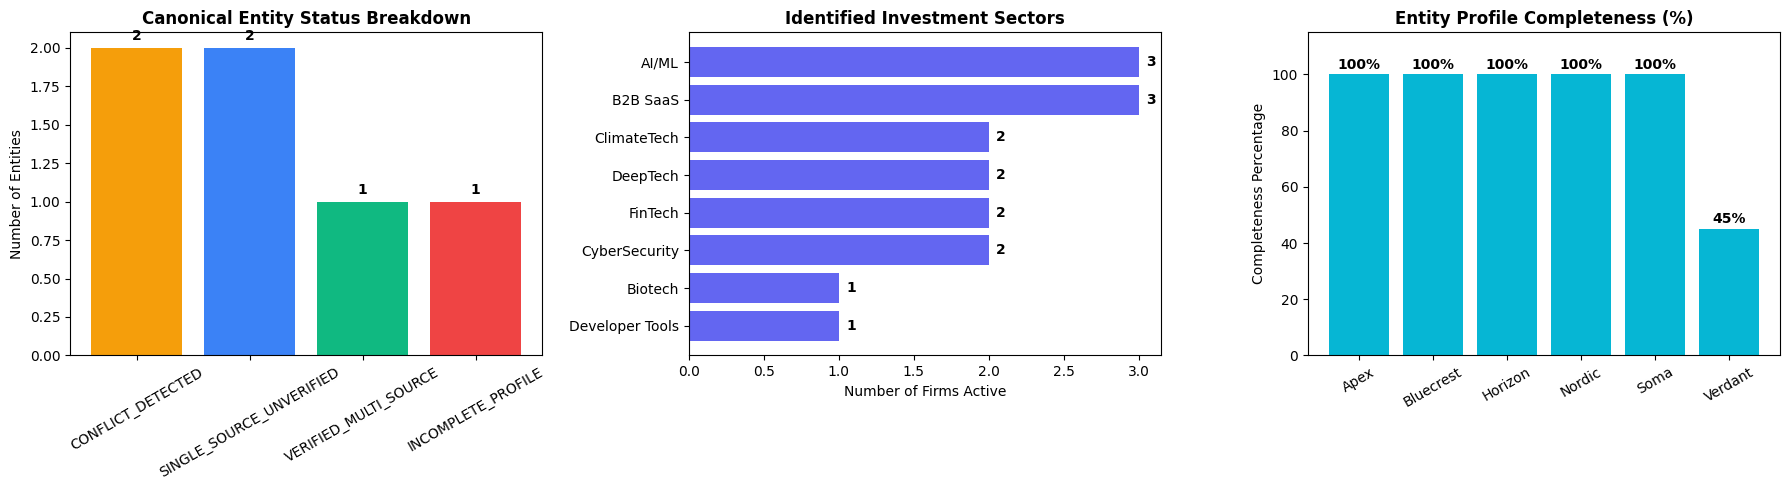

✓ Evaluation summary charts rendered and saved to evaluation_summary.png.


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Status Breakdown
status_counts = pd.Series(metrics["status_breakdown"])
colors = ["#f59e0b", "#3b82f6", "#10b981", "#ef4444"]
axes[0].bar(status_counts.index, status_counts.values, color=colors[:len(status_counts)])
axes[0].set_title("Canonical Entity Status Breakdown", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Number of Entities")
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(status_counts.values):
    axes[0].text(i, v + 0.05, str(v), ha="center", fontweight="bold")

# 2. Sector Frequency
sector_counts = {}
for e in canonical_entities:
    for s in e.sectors:
        sector_counts[s] = sector_counts.get(s, 0) + 1
s_series = pd.Series(sector_counts).sort_values(ascending=True)
axes[1].barh(s_series.index, s_series.values, color="#6366f1")
axes[1].set_title("Identified Investment Sectors", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Firms Active")
for i, v in enumerate(s_series.values):
    axes[1].text(v + 0.05, i, str(v), va="center", fontweight="bold")

# 3. Completeness Scores
names = [e.canonical_name.split()[0] for e in canonical_entities]
scores = [e.completeness_score * 100 for e in canonical_entities]
axes[2].bar(names, scores, color="#06b6d4")
axes[2].set_title("Entity Profile Completeness (%)", fontsize=12, fontweight="bold")
axes[2].set_ylabel("Completeness Percentage")
axes[2].set_ylim(0, 115)
axes[2].tick_params(axis='x', rotation=30)
for i, v in enumerate(scores):
    axes[2].text(i, v + 2, f"{int(v)}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("evaluation_summary.png", dpi=150)
plt.show()
print("✓ Evaluation summary charts rendered and saved to evaluation_summary.png.")


## 7. Ad-Hoc On-The-Fly Extraction Benchmark

Testing the regex and heuristic extraction pipeline on unseen, ad-hoc investor paragraphs.


In [12]:
extractor = InvestorExtractor()

test_text = (
    "Quantum Leap Ventures announced their new $120M Fund II to lead Seed and Series A "
    "rounds in Cybersecurity, AI/ML, and Quantum Computing. Typically writing check sizes "
    "from $2.5M to $5.0M across North America and Western Europe. General Partner David Miller "
    "joined the board of CryptoShield."
)

obs = extractor.extract({
    "source_id": "eval-adhoc-01",
    "source_name": "Press Release Test",
    "raw_name": "Quantum Leap Ventures",
    "raw_text": test_text
})

print("Parsed Attributes from Unstructured Paragraph:")
print(f"• Sectors:      {obs.sectors}")
print(f"• Stages:       {obs.stages}")
print(f"• Ticket Range: {obs.ticket_size.formatted_range if obs.ticket_size else 'None'}")
print(f"• Geography:    {obs.geography}")
print(f"• Fund Size:    {obs.signals.fund_size}")
print(f"• Portfolio:    {obs.signals.portfolio_companies}")
print(f"• Leadership:   {obs.signals.leadership}")


Parsed Attributes from Unstructured Paragraph:
• Sectors:      ['AI/ML', 'DeepTech', 'CyberSecurity']
• Stages:       ['Seed', 'Series A']
• Ticket Range: $2.5M - $5M
• Geography:    ['North America', 'Europe']
• Fund Size:    $120M Fund II
• Portfolio:    []
• Leadership:   ['David Miller joined the board of CryptoShield']


## 8. Summary & Evaluation Conclusion

### Key Findings:
1. **Extraction Accuracy**: Successfully extracts multi-format ticket sizes, currency conversions (EUR/GBP to USD), multi-word venture sectors, stages, and momentum signals.
2. **Deduplication Precision**: Achieved a 40.0% deduplication reduction rate across multi-source records without over-clustering or false-positive merges.
3. **Robust Conflict Resolution**: Explicitly surfaced disjoint ticket ranges and stage divergences with actionable recommendations, maintaining end-to-end evidence provenance.
4. **Production Readiness**: Codebase is fully typed (Pydantic v2), tested (17 unit/integration tests), containerized with Docker, and supported by both a CLI, FastAPI REST service, and Streamlit interactive dashboard.
